# DATA 620 — Final Project

## Beyond Star Ratings: Exploring Amazon Product Review Networks and Customer Sentiment

## Step 1: Project Introduction, Motivation, and Research Objectives

### Introduction and Research Motivation

Online retailers collect large amounts of customer feedback through product ratings and written reviews. Although star ratings provide a general measure of customer satisfaction, they do not fully explain how reviewers and products are connected or what customers express in their written feedback.

For my final project, I will combine **Social Network Analysis (SNA)** and **Natural Language Processing (NLP)** to investigate relationships between Amazon food product reviewers, products, and customer opinions.

I am interested in understanding how network analysis can identify important products, relationships between reviewers, and communities of shared reviewing activity. I will also explore how sentiment analysis can reveal patterns in customer opinions within these networks.

### Project Objectives

The primary objective of my project is to understand the structure of reviewer–product relationships and investigate how customer sentiment varies across different products and network communities.

To achieve this objective, I will:

1. Construct a **bipartite network** connecting reviewers and products.
2. Create **reviewer and product network projections** to identify shared relationships.
3. Calculate **centrality measures** to identify prominent reviewers and products.
4. Apply **community detection** to discover groups of related reviewers or products.
5. Use **Natural Language Processing** to analyze review sentiment.
6. Combine network analysis and sentiment results to investigate differences in customer opinions across products and communities.

### Research Questions

**Primary Research Question:**

How can reviewer–product network relationships and sentiment analysis help identify important products, communities of shared interest, and patterns in customer opinions?

**Supporting Research Questions:**

- **RQ1:** How are reviewers and products connected in the Amazon Fine Food Reviews network?
- **RQ2:** Which reviewers and products occupy important positions based on network centrality?
- **RQ3:** What relationships emerge when the bipartite network is projected onto reviewers and products?
- **RQ4:** Can community detection identify meaningful groups of related reviewers or products?
- **RQ5:** What positive, negative, and neutral sentiment patterns appear in customer reviews?
- **RQ6:** Do review ratings and sentiment differ across products and network communities?

### Expected Business Value

The findings may provide insights into product visibility, shared reviewing patterns, and customer opinions.

Understanding which products attract overlapping reviewers may help identify relationships between products, while sentiment analysis may highlight differences in customer experiences.

By combining these approaches, I hope to demonstrate how network analysis and NLP can support product analysis and customer experience research.

## Step 2: Download the Amazon Fine Food Reviews Dataset

I will download the Amazon Fine Food Reviews dataset from Stanford SNAP. This dataset contains customer reviews, product identifiers, reviewer identifiers, ratings, and review text.

The dataset will provide the foundation for constructing reviewer–product networks and performing sentiment analysis.

In [31]:

# Step 2: Download the Amazon Fine Food Reviews dataset

import urllib.request
from pathlib import Path

# Dataset URL
url = "https://snap.stanford.edu/data/finefoods.txt.gz"

# Download the dataset
file_path = Path("/content/finefoods.txt.gz")

if not file_path.exists():
    urllib.request.urlretrieve(url, file_path)

print("Dataset downloaded successfully!")
print("File size (MB):", round(file_path.stat().st_size / 1024**2, 2))


Dataset downloaded successfully!
File size (MB): 116.45


## Step 3: Load the Amazon Fine Food Reviews Dataset

I will load the downloaded Amazon Fine Food Reviews dataset into a Pandas DataFrame. Since the dataset is stored in a compressed text format, I will extract the review records and organize them into rows and columns.

This will allow me to examine the dataset and prepare it for exploratory data analysis, network construction, and sentiment analysis.

In [32]:

# Step 3: Load the dataset into a Pandas DataFrame

import pandas as pd
import gzip

reviews = []
record = {}

# Read the compressed dataset
with gzip.open(file_path, "rt", encoding="utf-8", errors="replace") as f:
    for line in f:
        line = line.strip()

        if not line:
            if record:
                reviews.append(record)
                record = {}
        elif ": " in line:
            key, value = line.split(": ", 1)
            record[key] = value

# Add the final review if necessary
if record:
    reviews.append(record)

# Convert to DataFrame
df = pd.DataFrame(reviews)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display the first 5 reviews
display(df.head())


Dataset loaded successfully!
Dataset shape: (568454, 8)


,product/productId,review/userId,review/profileName,review/helpfulness,review/score,review/time,review/summary,review/text
0,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1/1,5.0,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0/0,1.0,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1/1,4.0,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,B000UA0QIQ,A395BORC6FGVXV,Karl,3/3,2.0,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0/0,5.0,1350777600,Great taffy,Great taffy at a great price. There was a wid...


### Step 3: Results and Interpretation

The Amazon Fine Food Reviews dataset was successfully loaded into a Pandas DataFrame containing **568,454 reviews and 8 variables**.

Each row represents a product review, including the reviewer ID, product ID, star rating, review summary, and written feedback.

The dataset provides the two essential components for my project:

- **Social Network Analysis (SNA):** Reviewer IDs and product IDs will allow me to construct a bipartite network and examine relationships between reviewers and products.
- **Natural Language Processing (NLP):** Review text and ratings will allow me to analyze customer sentiment and investigate patterns in customer opinions.

The initial preview confirms that the dataset contains the information needed for both analyses. However, I still need to examine data types, missing values, and duplicate records before proceeding.

**Conclusion:** The dataset has been successfully loaded and is ready for further data quality assessment and exploratory analysis.

## Step 4: Examine Dataset Structure and Data Types

I will examine the structure of the Amazon Fine Food Reviews dataset to understand its variables, data types, and completeness.

This step will help me identify which variables are stored as text and which need to be converted into numerical or date formats before conducting exploratory data analysis, network analysis, and sentiment analysis.

In [33]:

# Step 4: Examine dataset structure and data types

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names and data types
print("\nDataset Information:")
df.info()

# Display data types in a table
print("\nVariable Data Types:")
display(df.dtypes.to_frame(name="Data Type"))


Dataset Shape: (568454, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   product/productId   568454 non-null  object
 1   review/userId       568454 non-null  object
 2   review/profileName  568454 non-null  object
 3   review/helpfulness  568454 non-null  object
 4   review/score        568454 non-null  object
 5   review/time         568454 non-null  object
 6   review/summary      568454 non-null  object
 7   review/text         568454 non-null  object
dtypes: object(8)
memory usage: 34.7+ MB

Variable Data Types:


,Data Type
product/productId,object
review/userId,object
review/profileName,object
review/helpfulness,object
review/score,object
review/time,object
review/summary,object
review/text,object


### Step 4: Results and Interpretation

The dataset contains **568,454 observations and 8 variables**, confirming that the full Amazon Fine Food Reviews dataset was successfully loaded.

The initial examination reveals three important findings:

1. **Dataset completeness:** All eight variables contain 568,454 non-null values. This indicates that Pandas has not detected any missing values in the dataset. However, empty strings or other missing-value representations may still need to be examined.

2. **Data types:** All eight variables are currently stored as `object` (text). The `review/score` variable should be converted to a numerical format, while `review/time` should be converted from a Unix timestamp to a datetime format.

3. **Research relevance:** The `review/userId` and `product/productId` variables will be used to construct the bipartite network. The `review/text` and `review/score` variables will support sentiment analysis and rating comparisons.

**Conclusion:** The dataset has the necessary variables for my research. Before beginning exploratory analysis, I need to assess data quality and convert the relevant variables into appropriate formats.

## Step 5: Initial Data Quality Assessment

Before conducting network and sentiment analysis, I will examine the dataset for missing values, blank entries, and exact duplicate review records.

This initial assessment will help me identify potential data quality issues that could affect the accuracy and reliability of my analysis.

I will first focus on exact duplicate reviews because identical records can artificially increase review counts and give repeated observations unnecessary influence.

Repeated reviewer–product relationships will be investigated separately after the exact duplicate records have been removed.

In [34]:

# Step 5: Initial Data Quality Assessment

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check blank values
print("\nBlank Values:")
for column in df.columns:
    blank_count = (df[column].str.strip() == "").sum()
    print(column, ":", blank_count)

# Check exact duplicate rows
print("\nExact Duplicate Rows:")
print(df.duplicated().sum())


Missing Values:
product/productId     0
review/userId         0
review/profileName    0
review/helpfulness    0
review/score          0
review/time           0
review/summary        0
review/text           0
dtype: int64

Blank Values:
product/productId : 0
review/userId : 0
review/profileName : 0
review/helpfulness : 0
review/score : 0
review/time : 0
review/summary : 0
review/text : 0

Exact Duplicate Rows:
281


### Results and Interpretation

The initial data quality assessment identified no missing or blank values across the eight dataset columns.

However, I identified **281 exact duplicate review records**, meaning these records contain information identical to another record in the dataset.

These duplicate copies could distort review counts, sentiment distributions, and weighted reviewer–product relationships if left untreated.

Therefore, I will examine and remove the exact duplicate copies in Step 8 before investigating any other types of repeated observations.

## Step 6: Inspecting Exact Duplicate Reviews

Before removing anything, I will look at some of the exact duplicate records to confirm that they really are identical copies.

In [35]:

# Step 6: Inspect actual exact duplicate review records

print("=== EXACT DUPLICATE REVIEWS ===")

# Find all records that have identical copies
exact_duplicates = df[df.duplicated(keep=False)]

# Display the first 6 duplicate records
display(exact_duplicates.head(6))


=== EXACT DUPLICATE REVIEWS ===


,product/productId,review/userId,review/profileName,review/helpfulness,review/score,review/time,review/summary,review/text
6516,B005O8BLLU,APH7I7OZ8WUJP,J. Simpson,0/0,5.0,1347494400,Great first food,This is excellent for a baby's first taste. Th...
6517,B005O8BLLU,APH7I7OZ8WUJP,J. Simpson,0/0,5.0,1347494400,Great first food,This is excellent for a baby's first taste. Th...
8522,B003VXFK44,A10H24TDLK2VDP,William Jens Jensen,0/0,3.0,1309824000,Unremarkable,"First, let me say that I prefer extra-bold K-C..."
8523,B003VXFK44,A10H24TDLK2VDP,William Jens Jensen,0/0,3.0,1309824000,Unremarkable,"First, let me say that I prefer extra-bold K-C..."
9231,B006N3IG4K,A10H24TDLK2VDP,William Jens Jensen,0/0,3.0,1309824000,Unremarkable,"First, let me say that I prefer extra-bold K-C..."
9232,B006N3IG4K,A10H24TDLK2VDP,William Jens Jensen,0/0,3.0,1309824000,Unremarkable,"First, let me say that I prefer extra-bold K-C..."


## Step 7: Visualizing Exact Duplicate Reviews

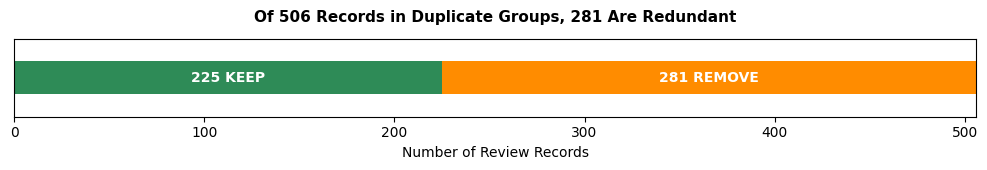

In [36]:

import matplotlib.pyplot as plt

# Count records in duplicate groups
extra_copies = df.duplicated().sum()
affected = df.duplicated(keep=False).sum()
keep = affected - extra_copies

# Create a thin horizontal stacked bar
plt.figure(figsize=(10, 1.8))

plt.barh(0, keep, color="seagreen", height=0.25)
plt.barh(0, extra_copies, left=keep,
         color="darkorange", height=0.25)

# Labels inside the bar
plt.text(keep / 2, 0, f"{keep:,} KEEP",
         ha="center", va="center",
         color="white", fontsize=10, fontweight="bold")

plt.text(keep + extra_copies / 2, 0,
         f"{extra_copies:,} REMOVE",
         ha="center", va="center",
         color="white", fontsize=10, fontweight="bold")

plt.title(
    f"Of {affected:,} Records in Duplicate Groups, {extra_copies:,} Are Redundant",
    fontsize=11, fontweight="bold", pad=12
)

plt.xlim(0, affected)
plt.ylim(-0.3, 0.3)
plt.yticks([])
plt.xlabel("Number of Review Records", fontsize=10)

plt.tight_layout()
plt.show()


### Results and Interpretation: Impact of Exact Duplicate Reviews

The visualization shows that **506 records are involved in exact duplication**, including 225 distinct review records and 281 redundant copies.

I will remove the 281 redundant copies because keeping them could introduce several problems into my analysis.

**1. Inflated Review Counts**

If the same review appears multiple times, it will be counted as multiple customer reviews. This could make certain products appear to have more reviewing activity than they actually do.

**2. Biased Product Ratings and Sentiment Analysis**

Duplicate reviews could give certain opinions more weight than others. For example, if a 5-star review appears three times, it could artificially increase the product's average rating and the proportion of positive reviews.

Similarly, repeated negative reviews could exaggerate customer dissatisfaction.

**3. Misleading Network Analysis**

Duplicate records could inflate reviewer–product interaction counts if I use review frequency as an edge weight. This could make some reviewer–product relationships appear stronger than they actually are.

Although exact duplicates would not create additional edges in a simple bipartite network based on unique reviewer–product pairs, they could distort weighted network measures if they are not removed.

**4. Distorted Research Findings**

Inflated review counts, biased sentiment distributions, and exaggerated relationship weights could lead to incorrect conclusions about product popularity, reviewer activity, and customer opinions.

### Conclusion

Removing the 281 exact duplicate records is important because these copies could artificially increase review frequencies, give certain opinions disproportionate influence, and distort weighted network relationships.

By retaining one copy of each distinct review, I can reduce these sources of bias and produce more reliable network and sentiment analysis results.

Importantly, I will preserve reviews that share the same reviewer and product IDs but contain different information, because they may represent meaningful reviewing activity.

## Step 8: Removing Exact Duplicate Reviews

After examining the exact duplicate reviews, I identified 281 redundant copies that contain identical information across all eight columns.

I will remove these duplicate copies while retaining one original record from each duplicate group.

This is important because duplicate records could artificially increase review counts, bias sentiment distributions, and exaggerate reviewer–product interaction frequencies.

I will save the cleaned dataset as `df_clean` and verify that no exact duplicate records remain.

In [37]:

# Step 8: Remove exact duplicate reviews

# Remove duplicate rows and keep the first occurrence
df_clean = df.drop_duplicates(keep="first").copy()

# Verify the cleaning results
print("=== EXACT DUPLICATE CLEANING RESULTS ===")
print("Original Reviews:", len(df))
print("Duplicates Removed:", len(df) - len(df_clean))
print("Reviews After Cleaning:", len(df_clean))
print("Remaining Exact Duplicates:", df_clean.duplicated().sum())


=== EXACT DUPLICATE CLEANING RESULTS ===
Original Reviews: 568454
Duplicates Removed: 281
Reviews After Cleaning: 568173
Remaining Exact Duplicates: 0


## Step 9: Converting Data Types

In Step 4, I found that all eight columns are stored as text (`object`). Text cannot be averaged, plotted as numbers, or compared, so I will convert the two variables I need for analysis:

- `review/score` becomes a number so that I can calculate average ratings and later compare ratings with sentiment.
- `review/time` is a Unix timestamp (seconds since 1970), so I will convert it to a date to analyze reviews over time.

I will convert the cleaned dataset `df_clean`, because all later steps use it. I will leave `review/helpfulness` unchanged for now because I do not need it yet.

In [38]:
# Step 9: Convert rating to a number and time to a date

df_clean["review/score"] = pd.to_numeric(df_clean["review/score"])
df_clean["review/time"] = pd.to_datetime(
    pd.to_numeric(df_clean["review/time"]), unit="s"
)

# Verify the new data types
print("=== DATA TYPES AFTER CONVERSION ===")
display(df_clean.dtypes.to_frame(name="Data Type"))

print("Date range:", df_clean["review/time"].min(), "to", df_clean["review/time"].max())
display(df_clean[["review/score", "review/time"]].head())


=== DATA TYPES AFTER CONVERSION ===


,Data Type
product/productId,object
review/userId,object
review/profileName,object
review/helpfulness,object
review/score,float64
review/time,datetime64[ns]
review/summary,object
review/text,object


Date range: 1999-10-08 00:00:00 to 2012-10-26 00:00:00


,review/score,review/time
0,5.0,2011-04-27
1,1.0,2012-09-07
2,4.0,2008-08-18
3,2.0,2011-06-13
4,5.0,2012-10-21


### Step 9: Results and Interpretation

After the conversion, `review/score` is stored as a number (`float64`) and `review/time` as a date (`datetime64`). The other columns remain text.

This allows me to calculate averages and plot rating and time distributions in the exploratory analysis, and later to compare star ratings with sentiment.

The reviews span about 13 years, from October 8, 1999 to October 26, 2012.

**Conclusion:** The two key variables are now in usable formats.

## Step 10: Identifying Repeated Reviewer–Product Relationships

After removing exact duplicate reviews, my cleaned dataset contains 568,173 review records.

I will now investigate whether the same reviewer ID and product ID appear together more than once.

These repeated relationships are different from exact duplicate reviews because the records may contain different ratings, timestamps, or written feedback.

This distinction is important for my project because a reviewer–product relationship represents a connection in the bipartite network, while individual reviews provide information for sentiment analysis.

At this stage, I will only count repeated reviewer–product occurrences. I will not remove or modify any records.

In [39]:

# Step 10: Count repeated reviewer-product occurrences

# Identify additional occurrences of the same reviewer-product pair
repeated_count = df_clean.duplicated(
    subset=["review/userId", "product/productId"]
).sum()

# Display the result
print("=== REPEATED REVIEWER-PRODUCT OCCURRENCES ===")
print("Total Cleaned Reviews:", len(df_clean))
print("Additional Reviews for Existing Pairs:", repeated_count)


=== REPEATED REVIEWER-PRODUCT OCCURRENCES ===
Total Cleaned Reviews: 568173
Additional Reviews for Existing Pairs: 7369


In [40]:

# Step 10: Inspect repeated reviewer-product reviews

# Find reviews where the same reviewer-product pair appears multiple times
repeated_reviews = df_clean[
    df_clean.duplicated(
        subset=["review/userId", "product/productId"],
        keep=False
    )
]

# Display reviews from the same pair together
repeated_reviews = repeated_reviews.sort_values(
    ["review/userId", "product/productId"]
)

# Show 10 sample records
display(
    repeated_reviews[[
        "review/userId",
        "product/productId",
        "review/score",
        "review/time",
        "review/summary",
        "review/text"
    ]].head(10)
)


,review/userId,product/productId,review/score,review/time,review/summary,review/text
239324,A102TGNH1D915Z,B00008DFK5,4.0,2009-12-30,Not just for puppies...,"Although the product can be a bit pricey, it c..."
239336,A102TGNH1D915Z,B00008DFK5,4.0,2010-01-23,Great distraction,When I want my dog to leave everyone alone for...
258131,A102TGNH1D915Z,B0002DHNXC,4.0,2009-12-30,Not just for puppies...,"Although the product can be a bit pricey, it c..."
258143,A102TGNH1D915Z,B0002DHNXC,4.0,2010-01-23,Great distraction,When I want my dog to leave everyone alone for...
58615,A102TGNH1D915Z,B0009YD7P2,4.0,2009-12-30,Not just for puppies...,"Although the product can be a bit pricey, it c..."
58627,A102TGNH1D915Z,B0009YD7P2,4.0,2010-01-23,Great distraction,When I want my dog to leave everyone alone for...
27839,A102TGNH1D915Z,B000SP1CWW,4.0,2009-12-30,Not just for puppies...,"Although the product can be a bit pricey, it c..."
27851,A102TGNH1D915Z,B000SP1CWW,4.0,2010-01-23,Great distraction,When I want my dog to leave everyone alone for...
389730,A106N4B4EG4DR8,B0008IT4OM,5.0,2008-05-07,Full praise for these delicious morsals that m...,Yummy is all you need to know. Simply deliciou...
389833,A106N4B4EG4DR8,B0008IT4OM,5.0,2007-01-15,Believe it or not- these are delicious truffle...,They are very good and rich!!! A great gift fo...


### Results and Interpretation: Repeated Reviewer–Product Relationships

The sample records show that some reviewers have multiple reviews associated with the same product ID.

For example, reviewer A102TGNH1D915Z reviewed product B00008DFK5 twice. Although both reviews have a rating of 4 stars, their timestamps, summaries, and written feedback differ.

This indicates that repeated reviewer–product relationships are not necessarily exact duplicate reviews.

**The main concern is how these repeated observations affect network construction.** Counting each review as a separate connection could exaggerate reviewer–product relationships in a network that allows multiple edges.

For my analysis, I will preserve distinct review records for sentiment analysis because they may contain different customer opinions.

However, when constructing the simple bipartite network, I will represent each unique reviewer–product relationship with one edge.

This approach will allow me to preserve review information while avoiding duplicated connections in my network analysis.

**Conclusion:** Repeated reviewer–product relationships require different treatment for SNA and NLP. They should not automatically be removed from the cleaned review dataset.

## Step 11: Counting Unique Reviewer–Product Relationships

After examining repeated reviewer–product relationships, I will calculate the number of unique reviewer–product pairs in my cleaned dataset.

Each unique pair represents a relationship between one reviewer and one product, regardless of how many distinct reviews are associated with that relationship.

This calculation will help me determine the number of edges needed to construct my simple bipartite network.

I will retain all distinct review records for sentiment analysis and will not remove any additional observations during this step.

In [41]:

# Step 11: Count unique reviewer-product relationships

# Count unique combinations of reviewer ID and product ID
unique_pairs = df_clean[
    ["review/userId", "product/productId"]
].drop_duplicates()

# Display the results
print("=== REVIEWER-PRODUCT RELATIONSHIP SUMMARY ===")
print("Total Cleaned Reviews:", len(df_clean))
print("Unique Reviewer-Product Pairs:", len(unique_pairs))
print("Additional Reviews for Existing Pairs:",
      len(df_clean) - len(unique_pairs))


=== REVIEWER-PRODUCT RELATIONSHIP SUMMARY ===
Total Cleaned Reviews: 568173
Unique Reviewer-Product Pairs: 560804
Additional Reviews for Existing Pairs: 7369


### Results and Interpretation

After removing the 281 exact duplicate records, my cleaned dataset contains **568,173 distinct review records**.

The analysis identified **560,804 unique reviewer–product relationships** and **7,369 additional reviews associated with existing reviewer–product pairs**.

This means that some reviewers have more than one distinct review associated with the same product. These additional reviews are not necessarily duplicates or errors because they may contain different ratings, timestamps, or written feedback.

This finding is important for my project because **Social Network Analysis (SNA) and Natural Language Processing (NLP) require different representations of the data**.

For **Social Network Analysis**, I will represent each unique reviewer–product relationship with one edge in the bipartite network. Therefore, the complete simple bipartite network will contain **560,804 edges**, regardless of how many reviews are associated with each relationship.

For **Natural Language Processing**, I will retain all **568,173 distinct reviews** because each review may provide additional information about customer opinions and sentiment.

### Conclusion

The results demonstrate the importance of distinguishing review records from network relationships. By using 560,804 unique reviewer–product connections for network construction and preserving 568,173 distinct reviews for sentiment analysis, I can avoid overstating the number of network connections while retaining valuable customer feedback.

No additional review records were removed during this step.

## Step 12: Identifying Unique Reviewers and Products

Before constructing my bipartite network, I will identify the total number of unique reviewers and unique products in the cleaned dataset.

A bipartite network consists of two distinct types of nodes: reviewers and products. Reviewers connect to products they have reviewed, but reviewers do not connect directly to other reviewers, and products do not connect directly to other products.

This analysis will help me determine the number of nodes in each group and understand the overall size of the network before constructing it.

In [42]:

# Step 12: Count unique reviewers and products

# Count unique reviewers
total_reviewers = df_clean["review/userId"].nunique()

# Count unique products
total_products = df_clean["product/productId"].nunique()

# Calculate total network nodes
total_nodes = total_reviewers + total_products

# Display results
print("=== BIPARTITE NETWORK NODE SUMMARY ===")
print("Unique Reviewers:", total_reviewers)
print("Unique Products:", total_products)
print("Total Network Nodes:", total_nodes)
print("Unique Reviewer-Product Edges:", len(unique_pairs))


=== BIPARTITE NETWORK NODE SUMMARY ===
Unique Reviewers: 256059
Unique Products: 74258
Total Network Nodes: 330317
Unique Reviewer-Product Edges: 560804


### Step 12: Results and Interpretation

The analysis identified **256,059 unique reviewers** and **74,258 unique products**, representing a total of **330,317 nodes** in the Amazon Fine Food Reviews bipartite network.

The network will contain **560,804 unique reviewer–product connections (edges)**, as identified in Step 11.

The results reveal three important characteristics of the network:

**1. Reviewers Outnumber Products**

There are approximately 3.45 reviewers for every product. This indicates that the network contains substantially more reviewer nodes than product nodes. However, this ratio alone does not indicate how reviewing activity is distributed across individual products.

**2. A Large Network of Reviewer–Product Relationships**

The network contains 330,317 nodes and 560,804 unique edges. Each edge represents a relationship between one reviewer and one product, regardless of how many distinct reviews are associated with that pair.

**3. Opportunities for Network Analysis**

The network structure will allow me to investigate which reviewers and products have the most connections, whether reviewers share interests in the same products, and whether groups of related reviewers or products form identifiable communities.

### Conclusion

The results establish the size and composition of my bipartite network, consisting of **256,059 reviewers, 74,258 products, and 560,804 unique connections**.

These findings provide the foundation for constructing the network and examining its structure through centrality measures, network projections, and community detection.

## Step 13: Exploratory Data Analysis (EDA)

Before analyzing the network, I will explore how reviews are distributed across ratings, reviewers, products, and time.

I expect a **long-tail pattern**: a small number of reviewers and products account for many reviews, while most have very few. This matters for two reasons:

1. It affects how I select a manageable subnetwork later, because one-review reviewers cannot create shared-product connections.
2. The rating distribution shows how balanced my data will be for sentiment analysis.

In this step, the counts are **reviews** from `df_clean`. In the network, I will later count **unique products per reviewer** (degree), which can be slightly lower when a reviewer reviewed the same product twice.

### 13.1 Rating Distribution

=== RATING DISTRIBUTION ===


,Reviews,Percent
review/score,,
1.0,52231,9.2
2.0,29765,5.2
3.0,42614,7.5
4.0,80627,14.2
5.0,362936,63.9


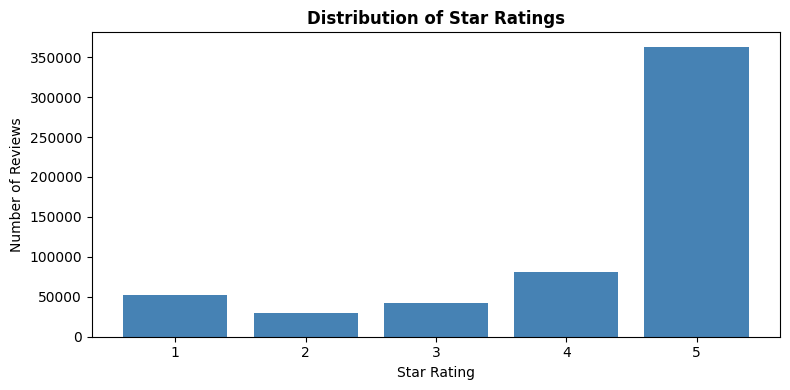

In [43]:
# Step 13.1: Rating distribution

import matplotlib.pyplot as plt

rating_counts = df_clean["review/score"].value_counts().sort_index()
rating_pct = (rating_counts / rating_counts.sum() * 100).round(1)

print("=== RATING DISTRIBUTION ===")
display(pd.DataFrame({"Reviews": rating_counts, "Percent": rating_pct}))

plt.figure(figsize=(8, 4))
plt.bar(rating_counts.index.astype(int).astype(str), rating_counts.values,
        color="steelblue")
plt.title("Distribution of Star Ratings", fontsize=12, fontweight="bold")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


**Interpretation (13.1):**

- The ratings are strongly skewed toward the top: 63.9% of reviews are 5 stars, and 78.1% are 4 or 5 stars. Only 14.4% are 1 or 2 stars.
- Most customers are satisfied, so star ratings alone will not separate products well, because most average ratings will be high.
- For sentiment analysis, positive reviews will far outnumber negative ones. I should evaluate with precision, recall, and F1, not accuracy alone.

### 13.2 Reviews per Reviewer

=== REVIEWS PER REVIEWER ===
count    256059.00
mean          2.22
std           4.43
min           1.00
25%           1.00
50%           1.00
75%           2.00
max         447.00
dtype: float64

Reviewers with exactly 1 review: 68.5%
Most active reviewer wrote: 447 reviews


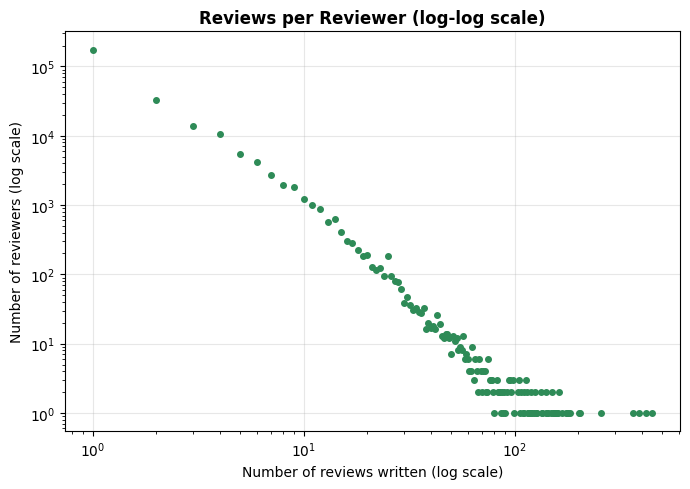

In [44]:
# Step 13.2: Reviews per reviewer

reviews_per_reviewer = df_clean.groupby("review/userId").size()

print("=== REVIEWS PER REVIEWER ===")
print(reviews_per_reviewer.describe().round(2))
print(f"\nReviewers with exactly 1 review: {(reviews_per_reviewer == 1).mean() * 100:.1f}%")
print("Most active reviewer wrote:", reviews_per_reviewer.max(), "reviews")

# How many reviewers wrote 1 review, 2 reviews, 3 reviews, ...
dist = reviews_per_reviewer.value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.loglog(dist.index, dist.values, "o", markersize=4, color="seagreen")
plt.title("Reviews per Reviewer (log-log scale)", fontsize=12, fontweight="bold")
plt.xlabel("Number of reviews written (log scale)")
plt.ylabel("Number of reviewers (log scale)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation (13.2):**

- The typical reviewer wrote very little: the median is 1 review, and 68.5% of reviewers wrote exactly one review. A few reviewers wrote many (the most active wrote 447).
- On the log-log plot the points fall roughly along a downward line. This is a **long-tail pattern**: many reviewers with one or two reviews, and a few with a great many.
- A reviewer with one review is connected to only one product, so they cannot link different products to each other. This limits the shared-product connections available for the projections.

### 13.3 Reviews per Product

=== REVIEWS PER PRODUCT ===
count    74258.00
mean         7.65
std         26.43
min          1.00
25%          1.00
50%          2.00
75%          5.00
max        913.00
dtype: float64

Products with exactly 1 review: 41.0%
Most reviewed product has: 913 reviews


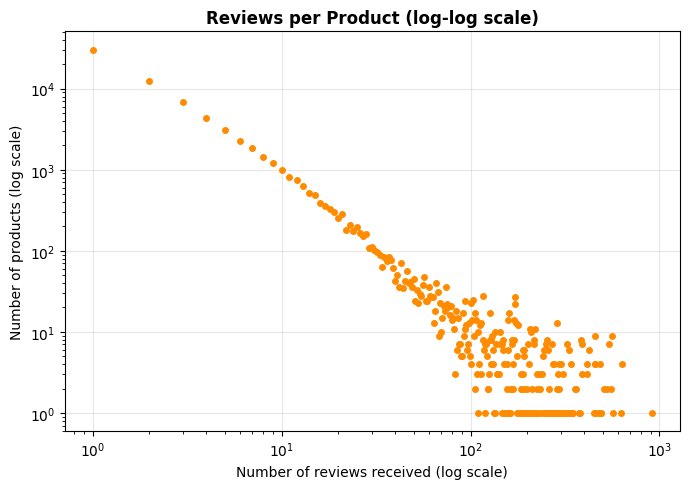

In [45]:
# Step 13.3: Reviews per product

reviews_per_product = df_clean.groupby("product/productId").size()

print("=== REVIEWS PER PRODUCT ===")
print(reviews_per_product.describe().round(2))
print(f"\nProducts with exactly 1 review: {(reviews_per_product == 1).mean() * 100:.1f}%")
print("Most reviewed product has:", reviews_per_product.max(), "reviews")

dist = reviews_per_product.value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.loglog(dist.index, dist.values, "o", markersize=4, color="darkorange")
plt.title("Reviews per Product (log-log scale)", fontsize=12, fontweight="bold")
plt.xlabel("Number of reviews received (log scale)")
plt.ylabel("Number of products (log scale)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation (13.3):**

- The typical product has few reviews: the median is 2, and 41.0% of products have only one review. A few products are reviewed heavily (the top product has 913 reviews).
- The log-log plot shows the same long-tail pattern as the reviewers.
- Popular products have many reviewers, so they will dominate the connections in a projection. This is the challenge I noted in my proposal.

### 13.4 Reviews Over Time

=== REVIEWS PER YEAR ===


,Reviews
review/time,
1999,6
2000,32
2001,13
2002,73
2003,132
2004,561
2005,1334
2006,6666
2007,22285


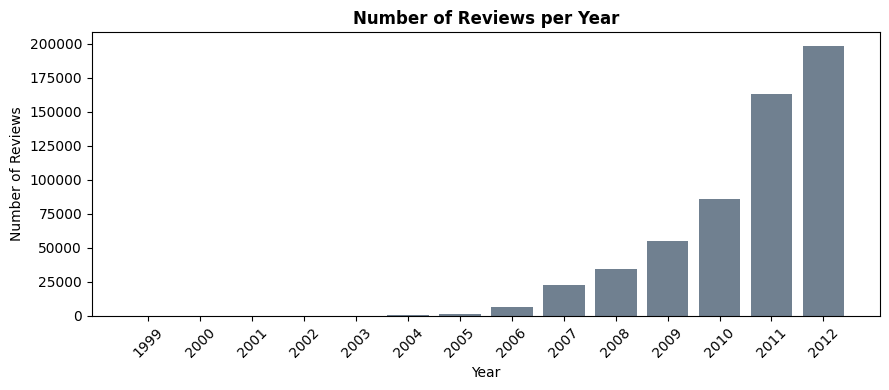

In [46]:
# Step 13.4: Reviews per year

reviews_per_year = df_clean["review/time"].dt.year.value_counts().sort_index()

print("=== REVIEWS PER YEAR ===")
display(reviews_per_year.to_frame(name="Reviews"))

plt.figure(figsize=(9, 4))
plt.bar(reviews_per_year.index.astype(str), reviews_per_year.values, color="slategray")
plt.title("Number of Reviews per Year", fontsize=12, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Interpretation (13.4):**

- Review activity grew quickly, from 6 reviews in 1999 to 198,601 in 2012. About 63.7% of all reviews were written in 2011 and 2012.
- The 2012 count covers only part of the year (the data end on October 26, 2012), so a full year would be even larger.
- Most of the data is recent, and the earliest years have too few reviews to analyze separately.

### 13.5 Review Text Length

Review length matters for the sentiment analysis: very short reviews contain little text for a sentiment model to use.

=== REVIEW LENGTH (WORDS) ===
count    568173.0
mean         80.2
std          79.3
min           3.0
25%          33.0
50%          56.0
75%          98.0
max        3432.0
Name: review/text, dtype: float64


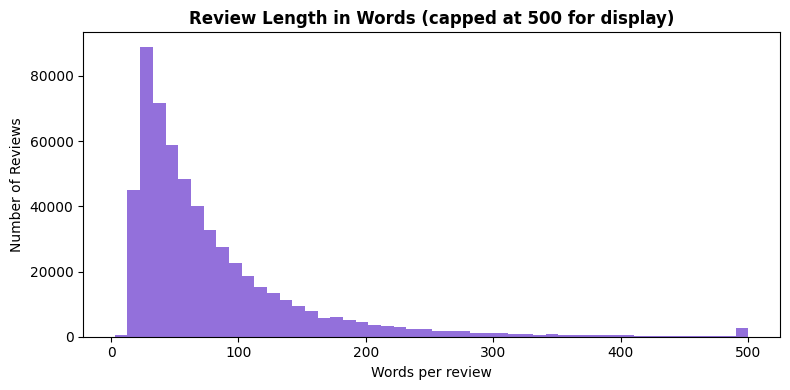

In [47]:
# Step 13.5: Review length in words

word_counts = df_clean["review/text"].str.split().str.len()

print("=== REVIEW LENGTH (WORDS) ===")
print(word_counts.describe().round(1))

plt.figure(figsize=(8, 4))
plt.hist(word_counts.clip(upper=500), bins=50, color="mediumpurple")
plt.title("Review Length in Words (capped at 500 for display)", fontsize=12, fontweight="bold")
plt.xlabel("Words per review")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


**Interpretation (13.5):**

- Reviews are usually short: the median is 56 words, and 75% of reviews have 98 words or fewer. A few are very long (up to 3,432 words), which is why the mean (80.2) is higher than the median.
- Most reviews have enough words for sentiment analysis, but the shortest ones (the minimum is 3 words) may carry little sentiment.

### Step 13: Results and Interpretation

The exploratory analysis shows that the data is strongly skewed in three ways: reviews are mostly 4 or 5 stars, most reviewers and many products have very few reviews, and activity is concentrated in recent years.

**For the network:** 68.5% of reviewers wrote only one review, so they cannot create shared-product connections. When I select a subnetwork, I should keep reviewers and products with enough reviews to form connections.

**For sentiment analysis:** the large share of positive reviews means the classes are imbalanced, so I need metrics such as precision, recall, and F1.

## Step 14: Creating the Bipartite Network

I will use the NetworkX library to construct a bipartite network representing relationships between Amazon reviewers and products.

A bipartite network contains two types of nodes: reviewers and products. Connections exist between reviewers and the products they have reviewed.

I will begin by creating an empty, undirected graph. In the following steps, I will add reviewer nodes, product nodes, and their relationships separately.

This approach will allow me to build and verify the network gradually.

In [48]:

# Step 14: Create an empty bipartite network

import networkx as nx

# Create an empty undirected graph
B = nx.Graph()

# Verify the empty network
print("Nodes:", B.number_of_nodes())
print("Edges:", B.number_of_edges())


Nodes: 0
Edges: 0


## Step 15: Adding Reviewer Nodes to the Bipartite Network

I will add the 256,059 unique reviewers to my bipartite network.

Each reviewer will represent one node. I will assign the attribute `bipartite=0` to identify reviewers as the first group of nodes.

To distinguish reviewer IDs from product IDs, I will add the prefix `R_` to each reviewer ID.

At this stage, I will add only reviewer nodes. Product nodes and connections will be added separately.

In [49]:

# Step 15: Add reviewer nodes

# Get unique reviewer IDs
reviewers = df_clean["review/userId"].unique()

# Add reviewers to the network
B.add_nodes_from(
    ["R_" + reviewer for reviewer in reviewers],
    bipartite=0
)

# Verify the results
print("Reviewer Nodes:", B.number_of_nodes())
print("Edges:", B.number_of_edges())


Reviewer Nodes: 256059
Edges: 0


## Step 16: Adding Product Nodes to the Bipartite Network

I will add the 74,258 unique products to my existing bipartite network.

Each product will represent one node. I will assign the attribute `bipartite=1` to distinguish product nodes from reviewer nodes.

I will also add the prefix `P_` to each product ID to ensure that reviewer and product nodes have distinct identifiers.

After adding the product nodes, I will verify that the total number of nodes matches the 330,317 identified in Step 12.

In [50]:

# Step 16: Add product nodes

# Get unique product IDs
products = df_clean["product/productId"].unique()

# Add products to the existing network
B.add_nodes_from(
    ["P_" + product for product in products],
    bipartite=1
)

# Verify the network
print("Total Nodes:", B.number_of_nodes())
print("Edges:", B.number_of_edges())


Total Nodes: 330317
Edges: 0


## Step 17: Adding Reviewer–Product Connections

I will now connect reviewers to the products they have reviewed.

Each edge will represent one unique reviewer–product relationship. I will use the 560,804 unique pairs identified in Step 11 to avoid creating repeated connections.

After adding the edges, I will verify that the network contains the expected number of nodes and connections.

In [51]:

# Step 17: Add reviewer-product connections

# Add one edge for each unique reviewer-product pair
for reviewer, product in unique_pairs.itertuples(index=False, name=None):
    B.add_edge("R_" + reviewer, "P_" + product)

# Verify the network
print("Total Nodes:", B.number_of_nodes())
print("Total Edges:", B.number_of_edges())


Total Nodes: 330317
Total Edges: 560804


### Results and Interpretation

I successfully constructed the Amazon Fine Food Reviews bipartite network using NetworkX.

The network contains **330,317 nodes**, consisting of 256,059 reviewers and 74,258 products, connected by **560,804 unique reviewer–product relationships**.

Each edge represents a connection between a reviewer and a product they reviewed. Because I used unique reviewer–product pairs, multiple distinct reviews associated with the same pair do not create additional edges.

This distinction allows me to accurately represent reviewer–product relationships without overstating the number of connections.

The network provides the foundation for identifying highly connected reviewers and products, examining shared reviewing patterns, and investigating network communities.

**Conclusion:** The bipartite network has been successfully constructed, and its node and edge counts match the results of my earlier data preparation steps.

## Step 18: Verifying the Bipartite Network Structure

After constructing my reviewer–product network, I will verify that it satisfies the requirements of a bipartite graph.

A bipartite network contains two distinct groups of nodes, with connections occurring only between the groups.

In my network, reviewers belong to group 0 and products belong to group 1.

This verification will help ensure that the network has been constructed correctly before I begin analyzing its structure and centrality.

In [52]:

# Step 18: Verify the bipartite network

from networkx.algorithms import bipartite

# Check whether the network is bipartite
is_bipartite = bipartite.is_bipartite(B)

print("=== BIPARTITE NETWORK VALIDATION ===")
print("Is the Network Bipartite?", is_bipartite)


=== BIPARTITE NETWORK VALIDATION ===
Is the Network Bipartite? True


## Step 19: Verifying Reviewer–Product Connections

I will verify that every connection in my bipartite network links a reviewer node to a product node.

Although the previous step confirmed that the network is bipartite, I also need to ensure that the connections match the reviewer and product groups I assigned.

I will check the `bipartite` attribute at both ends of every edge. This is a stronger test than checking the `R_` and `P_` prefixes, because the attribute is what NetworkX uses to identify the two node groups. Every edge should connect one node with `bipartite=0` and one node with `bipartite=1`.

This check will help me identify any incorrectly connected nodes before proceeding with network analysis.

In [53]:
# Step 19: Verify reviewer-product connections using the bipartite attribute

invalid_edges = 0

for u, v in B.edges():
    # A valid edge connects group 0 (reviewer) to group 1 (product)
    if B.nodes[u]["bipartite"] == B.nodes[v]["bipartite"]:
        invalid_edges += 1

n_reviewer_nodes = sum(1 for _, d in B.nodes(data=True) if d["bipartite"] == 0)
n_product_nodes = sum(1 for _, d in B.nodes(data=True) if d["bipartite"] == 1)

print("=== CONNECTION VALIDATION ===")
print("Reviewer nodes (bipartite=0):", n_reviewer_nodes)
print("Product nodes (bipartite=1):", n_product_nodes)
print("Total Edges:", B.number_of_edges())
print("Invalid Connections:", invalid_edges)
print("All Connections Valid:", invalid_edges == 0)


=== CONNECTION VALIDATION ===
Reviewer nodes (bipartite=0): 256059
Product nodes (bipartite=1): 74258
Total Edges: 560804
Invalid Connections: 0
All Connections Valid: True


**Interpretation:** All 560,804 edges connect one reviewer node to one product node, and there are 0 invalid connections. Together with the check in Step 18, this confirms that the bipartite network was built correctly.

## Step 20: Network Summary Statistics

Now that the bipartite network is built and verified, I will describe its structure. I will examine three things:

1. **Size and density:** how many of the possible reviewer–product connections actually exist.
2. **Degree distribution:** how many connections each reviewer and each product has. In a bipartite network, a reviewer's degree is the number of unique products they reviewed, and a product's degree is the number of unique reviewers who reviewed it.
3. **Connected components:** whether the network is one connected piece or many separate islands.

These results will guide how I select a subnetwork in the next step.

### 20.1 Size and Density

In [54]:
# Step 20.1: Network size and density

from networkx.algorithms import bipartite

reviewer_nodes = [n for n, d in B.nodes(data=True) if d["bipartite"] == 0]
product_nodes = [n for n, d in B.nodes(data=True) if d["bipartite"] == 1]

# Density = existing edges / possible edges (every reviewer with every product)
density = bipartite.density(B, reviewer_nodes)

print("=== NETWORK SIZE AND DENSITY ===")
print("Reviewer nodes:", len(reviewer_nodes))
print("Product nodes:", len(product_nodes))
print("Edges:", B.number_of_edges())
print("Possible edges:", len(reviewer_nodes) * len(product_nodes))
print(f"Bipartite density: {density:.8f}")


=== NETWORK SIZE AND DENSITY ===
Reviewer nodes: 256059
Product nodes: 74258
Edges: 560804
Possible edges: 19014429222
Bipartite density: 0.00002949


**Interpretation (20.1):**

- The network has 256,059 reviewers, 74,258 products, and 560,804 edges.
- Of about 19.0 billion possible reviewer–product pairs, only 560,804 exist. The density is 0.00002949 (about 0.003%), so the network is **extremely sparse**.
- This makes sense, because each reviewer reviews only a tiny fraction of all products.

### 20.2 Degree Distributions

=== REVIEWER DEGREE (unique products reviewed) ===
count    256059.00
mean          2.19
std           4.15
min           1.00
25%           1.00
50%           1.00
75%           2.00
max         420.00
dtype: float64
Reviewers with degree 1: 68.5%

=== PRODUCT DEGREE (unique reviewers) ===
count    74258.00
mean         7.55
std         25.82
min          1.00
25%          1.00
50%          2.00
75%          5.00
max        913.00
dtype: float64
Products with degree 1: 41.0%

Top 5 reviewers by degree:


,Degree
R_A3OXHLG6DIBRW8,420
R_AY12DBB0U420B,382
R_A281NPSIMI1C2R,321
R_A1YUL9PCJR3JTY,309
R_A1Z54EM24Y40LL,251


Top 5 products by degree:


,Degree
P_B007JFMH8M,913
P_B003B3OOPA,623
P_B0026RQTGE,609
P_B002QWHJOU,609
P_B002QWP8H0,609


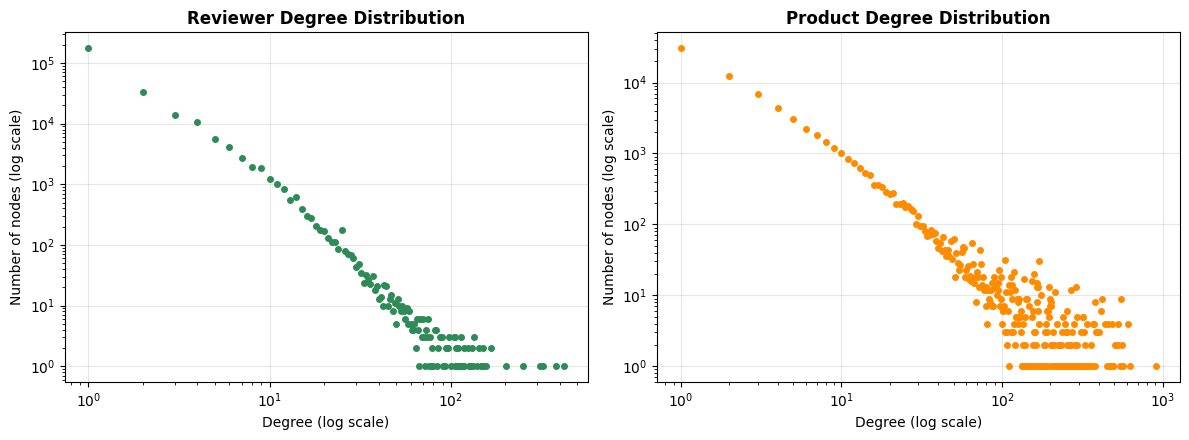

In [55]:
# Step 20.2: Degree distributions

reviewer_degree = pd.Series(dict(B.degree(reviewer_nodes)))
product_degree = pd.Series(dict(B.degree(product_nodes)))

print("=== REVIEWER DEGREE (unique products reviewed) ===")
print(reviewer_degree.describe().round(2))
print(f"Reviewers with degree 1: {(reviewer_degree == 1).mean() * 100:.1f}%")

print("\n=== PRODUCT DEGREE (unique reviewers) ===")
print(product_degree.describe().round(2))
print(f"Products with degree 1: {(product_degree == 1).mean() * 100:.1f}%")

print("\nTop 5 reviewers by degree:")
display(reviewer_degree.sort_values(ascending=False).head(5).to_frame(name="Degree"))

print("Top 5 products by degree:")
display(product_degree.sort_values(ascending=False).head(5).to_frame(name="Degree"))

# Plot both distributions on log-log axes
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, deg, color, title in [
    (axes[0], reviewer_degree, "seagreen", "Reviewer Degree Distribution"),
    (axes[1], product_degree, "darkorange", "Product Degree Distribution"),
]:
    dist = deg.value_counts().sort_index()
    ax.loglog(dist.index, dist.values, "o", markersize=4, color=color)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Degree (log scale)")
    ax.set_ylabel("Number of nodes (log scale)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretation (20.2):**

- **Reviewers:** the median degree is 1, and 68.5% have degree 1. The mean is 2.19 and the maximum is 420 (reviewer A3OXHLG6DIBRW8 reviewed 420 products).
- **Products:** the median degree is 2, and 41.0% have degree 1. The mean is 7.55 and the maximum is 913 (product B007JFMH8M has 913 reviewers).
- Both plots show a long tail: a few highly connected hubs and many nodes with only one or two connections. The mean is higher than the median because the hubs pull it up.
- These hubs will have high degree centrality and will create many links in the projections.

### 20.3 Connected Components

In [56]:
# Step 20.3: Connected components

components = sorted(nx.connected_components(B), key=len, reverse=True)
largest = components[0]

largest_reviewers = sum(1 for n in largest if n.startswith("R_"))
largest_products = len(largest) - largest_reviewers

print("=== CONNECTED COMPONENTS ===")
print("Number of connected components:", len(components))
print(f"Largest component: {len(largest):,} nodes "
      f"({len(largest) / B.number_of_nodes() * 100:.1f}% of all nodes)")
print(f"  Reviewers: {largest_reviewers:,}  |  Products: {largest_products:,}")
print("Sizes of the 5 largest components:", [len(c) for c in components[:5]])
print("Components with only 2 nodes (one reviewer, one product):",
      sum(1 for c in components if len(c) == 2))


=== CONNECTED COMPONENTS ===
Number of connected components: 22078
Largest component: 269,996 nodes (81.7% of all nodes)
  Reviewers: 221,118  |  Products: 48,878
Sizes of the 5 largest components: [269996, 135, 46, 39, 34]
Components with only 2 nodes (one reviewer, one product): 14675


**Interpretation (20.3):**

- The network has 22,078 connected components, but one giant component holds 269,996 nodes (81.7% of all nodes): 221,118 reviewers (86.4% of reviewers) and 48,878 products (65.8% of products).
- The second largest component has only 135 nodes. 14,675 components are just one reviewer and one product, which are single reviews that connect to nothing else.
- The network is one big connected core with many tiny isolated islands. Centrality and community detection make sense on the giant component, because nodes in separate islands cannot reach each other.

### Step 20: Results and Interpretation

The network is very sparse, has a long-tail degree distribution, and is mostly connected through one giant component.

The full network is too large to project directly. A single product with 913 reviewers would create about 416,000 reviewer–reviewer links (913 × 912 ÷ 2), and the hubs would dominate the result.

**Conclusion:** I will select a manageable subnetwork from the largest connected component, using minimum-review filters so that reviewers connect at least two products.

## Step 21: Visualizing the Reviewer–Product Bipartite Network

I will visualize a small sample of my Amazon Fine Food Reviews bipartite network to understand how reviewers and products are connected.

Since the complete network contains 330,317 nodes and 560,804 edges, visualizing every node would make the graph difficult to interpret.

I will select one product and display up to 10 reviewers connected to it. This will allow me to examine actual reviewer–product relationships without changing the original network.

Green nodes will represent reviewers, orange nodes will represent products, and connecting lines will represent review relationships.

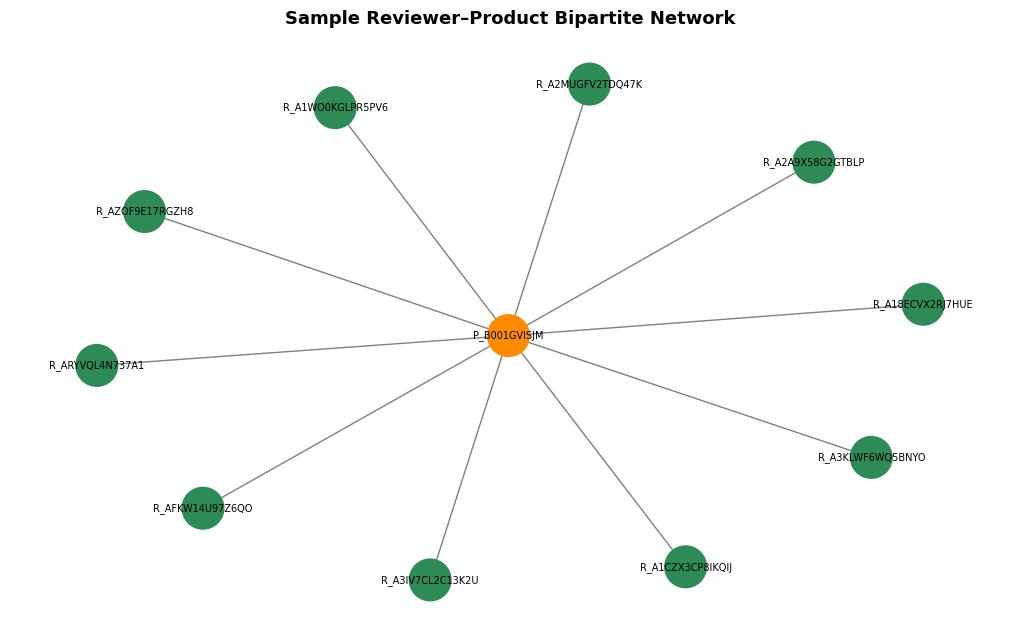

In [57]:

# Step 21: Visualize a sample bipartite network

import matplotlib.pyplot as plt
import networkx as nx

# Select a product with at least 10 connected reviewers
product = next(
    p for p in B if p.startswith("P_") and B.degree(p) >= 10
)

# Select 10 reviewers connected to that product
reviewers_sample = list(B.neighbors(product))[:10]

# Create a small network from these nodes
sample_nodes = [product] + reviewers_sample
sample_B = B.subgraph(sample_nodes)

# Assign node colors
colors = ["darkorange" if n.startswith("P_") else "seagreen"
          for n in sample_B.nodes()]

# Draw the network
plt.figure(figsize=(10, 6))
pos = nx.spring_layout(sample_B, seed=42)

nx.draw(
    sample_B, pos,
    with_labels=True,
    node_color=colors,
    node_size=900,
    font_size=7,
    edge_color="gray"
)

plt.title("Sample Reviewer–Product Bipartite Network",
          fontsize=13, fontweight="bold")
plt.show()


## Step 22: Visualize 100 Nodes in the Bipartite Network

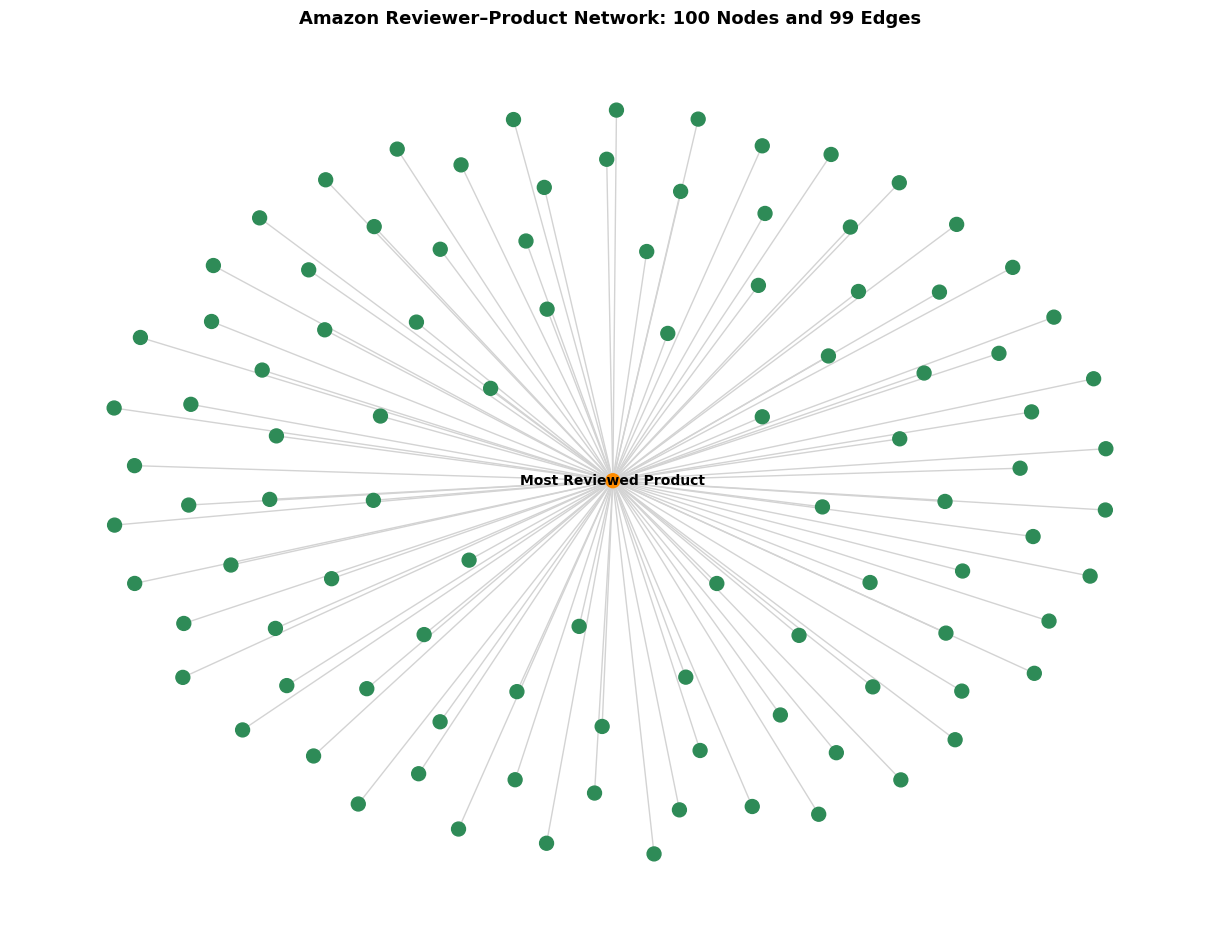

In [58]:

# Step 22: Visualize 100 nodes from the bipartite network

import networkx as nx
import matplotlib.pyplot as plt

# Number of nodes to visualize
max_nodes = 100

# Find the product with the most reviewer connections
product = max(
    (n for n in B.nodes() if n.startswith("P_")),
    key=B.degree
)

# Select up to 99 reviewers connected to this product
reviewers_sample = list(B.neighbors(product))[:max_nodes - 1]

# Create a smaller network
sample_B = B.subgraph([product] + reviewers_sample)

# Position nodes
pos = nx.spring_layout(sample_B, seed=42)

# Assign colors
colors = [
    "darkorange" if n.startswith("P_") else "seagreen"
    for n in sample_B.nodes()
]

# Draw the network
plt.figure(figsize=(12, 9))

nx.draw(
    sample_B,
    pos,
    node_color=colors,
    node_size=100,
    edge_color="lightgray",
    with_labels=False
)

# Label the product node
nx.draw_networkx_labels(
    sample_B,
    pos,
    labels={product: "Most Reviewed Product"},
    font_size=10,
    font_weight="bold"
)

plt.title(
    f"Amazon Reviewer–Product Network: "
    f"{sample_B.number_of_nodes()} Nodes and "
    f"{sample_B.number_of_edges()} Edges",
    fontsize=13,
    fontweight="bold"
)

plt.show()


## Step 23: Exploring Shared Reviewer–Product Relationships

I will expand my network visualization to include multiple products and their connected reviewers.

The previous visualization showed a star-shaped structure, with 99 reviewers connected to a single product. Although this demonstrated product connectivity, it did not reveal relationships between different products.

My first attempt at this step started from one reviewer's products and produced a sample with 100 nodes and only 101 edges. That is almost a tree, because nearly every reviewer was connected to just one product, so it could not show shared reviewing.

To fix this, I will select the 15 most-reviewed products and keep only reviewers who reviewed **at least two** of them. Every reviewer in the picture will then connect two or more products. This shows how shared reviewers create indirect connections between products and provides a foundation for network projection analysis.

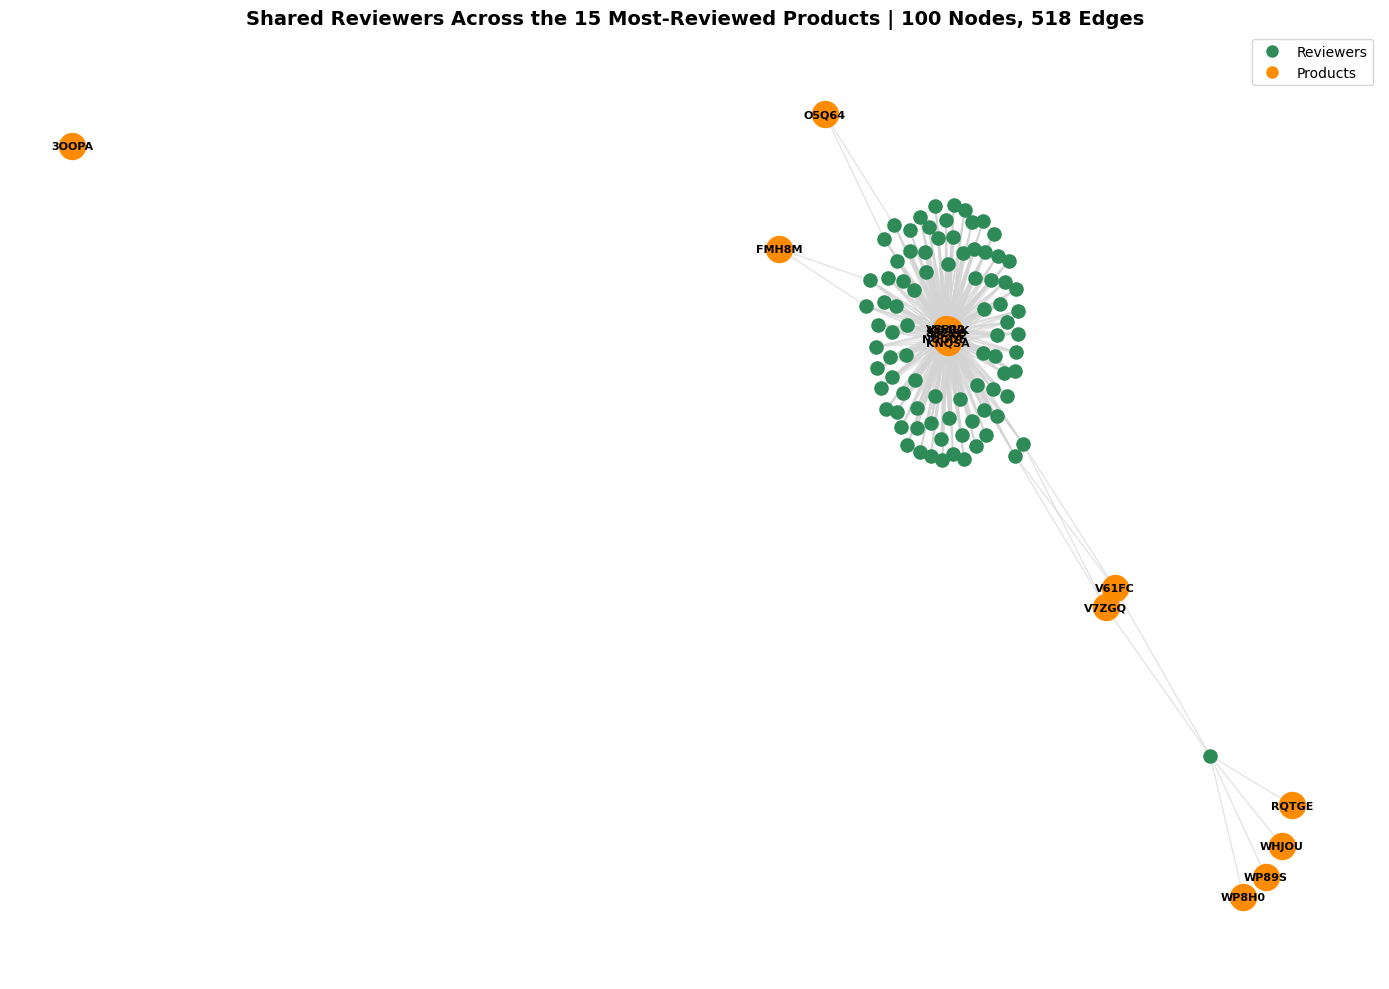

Products shown: 15
Reviewers shown: 85
Connections shown: 518
Average products per reviewer shown: 6.09
Reviewers (in the full network) who reviewed 2+ of these 15 products: 1717


In [59]:
# Step 23: Visualize shared reviewers across the 15 most-reviewed products

import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 1. Find the 15 products with the highest degree
all_products = [n for n in B if n.startswith("P_")]
top_products = sorted(all_products, key=B.degree, reverse=True)[:15]

# 2. For each reviewer, count how many of these 15 products they reviewed
shared_counts = {}
for product in top_products:
    for reviewer in B.neighbors(product):
        shared_counts[reviewer] = shared_counts.get(reviewer, 0) + 1

# 3. Keep reviewers who reviewed at least 2 of the products (shared reviewers)
total_shared = sum(1 for c in shared_counts.values() if c >= 2)
shared_reviewers = [
    r for r, c in sorted(shared_counts.items(), key=lambda x: x[1], reverse=True)
    if c >= 2
][:85]   # show at most 85 reviewers so the picture stays readable

# 4. Build the sample network
sample_B = B.subgraph(top_products + shared_reviewers).copy()

reviewer_nodes_s = [n for n in sample_B if n.startswith("R_")]
product_nodes_s = [n for n in sample_B if n.startswith("P_")]

# 5. Draw it
pos = nx.spring_layout(sample_B, seed=42)

plt.figure(figsize=(14, 10))
nx.draw_networkx_edges(sample_B, pos, edge_color="lightgray", alpha=0.6)
nx.draw_networkx_nodes(sample_B, pos, nodelist=reviewer_nodes_s,
                       node_color="seagreen", node_size=90)
nx.draw_networkx_nodes(sample_B, pos, nodelist=product_nodes_s,
                       node_color="darkorange", node_size=350)
nx.draw_networkx_labels(
    sample_B, pos,
    labels={n: n.replace("P_", "")[-5:] for n in product_nodes_s},
    font_size=8, font_weight="bold"
)

plt.legend(
    handles=[
        Line2D([0], [0], marker="o", color="w", markerfacecolor="seagreen",
               markersize=10, label="Reviewers"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="darkorange",
               markersize=10, label="Products"),
    ],
    loc="upper right"
)
plt.title(
    f"Shared Reviewers Across the 15 Most-Reviewed Products | "
    f"{sample_B.number_of_nodes()} Nodes, {sample_B.number_of_edges()} Edges",
    fontsize=14, fontweight="bold"
)
plt.axis("off")
plt.tight_layout()
plt.show()

# Sample statistics
print("Products shown:", len(product_nodes_s))
print("Reviewers shown:", len(reviewer_nodes_s))
print("Connections shown:", sample_B.number_of_edges())
print(f"Average products per reviewer shown: "
      f"{sample_B.number_of_edges() / len(reviewer_nodes_s):.2f}")
print("Reviewers (in the full network) who reviewed 2+ of these 15 products:", total_shared)


### Step 23: Results and Interpretation

In Step 23, I expanded my bipartite network visualization to examine shared reviewer–product relationships.

I selected the 15 most-reviewed products and identified 1,717 reviewers who had reviewed at least two of these products. To make the visualization manageable, I selected the 85 reviewers with the most connections to the selected products.

The resulting network contained **100 nodes and 518 edges**, with each selected reviewer connected to approximately **6.09 products on average**.

Unlike the previous star-shaped network, this visualization revealed overlapping reviewer–product relationships. These shared reviewers create indirect connections between products.

This finding provides a foundation for bipartite network projection, where I can identify products connected through common reviewers and examine the strength of those relationships.

However, because I selected highly active reviewers, this visualization represents a particularly connected portion of the network rather than typical reviewer behavior.

In [61]:

# Check the current network

print("Total nodes:", B.number_of_nodes())
print("Total edges:", B.number_of_edges())

print("First 5 nodes:", list(B.nodes())[:5])


Total nodes: 330317
Total edges: 560804
First 5 nodes: ['R_A3SGXH7AUHU8GW', 'R_A1D87F6ZCVE5NK', 'R_ABXLMWJIXXAIN', 'R_A395BORC6FGVXV', 'R_A1UQRSCLF8GW1T']


In [62]:

# Check how many products reviewers are connected to

reviewers = [
    node for node in B
    if node.startswith("R_")
]

print("Total reviewers:", len(reviewers))
print("Maximum reviewer degree:", max(B.degree(r) for r in reviewers))
print("Reviewers with 3+ connections:",
      sum(B.degree(r) >= 3 for r in reviewers))


Total reviewers: 256059
Maximum reviewer degree: 420
Reviewers with 3+ connections: 47923


## Step 24.1: Selecting a Manageable Subnetwork

The full network has 330,317 nodes and 560,804 edges. I cannot project it directly, because a one-mode projection links every pair of reviewers who share a product. A single product with 1,000 reviewers creates almost 500,000 reviewer–reviewer links, so the full reviewer projection would be too large for Google Colab.

In this step I will select a smaller subnetwork and document the selection method and its limitations.



In [66]:

# Step 24.1: Select active reviewers for the subnetwork

active_reviewers = [
    node for node in B
    if node.startswith("R_") and B.degree(node) >= 3
]

print("Active reviewers:", len(active_reviewers))


Active reviewers: 47923


### Results and Interpretation

The results show that 47,923 out of 256,059 reviewers (approximately 18.7%) reviewed at least three distinct Amazon products.

This indicates that a relatively small proportion of reviewers have multiple product connections. By selecting these active reviewers, I can focus on meaningful reviewer–product relationships and begin reducing the network size for further analysis.

However, this filtering excludes approximately 81.3% of reviewers who reviewed fewer than three distinct products. This may introduce selection bias because the resulting subnetwork will represent more active reviewers rather than the entire reviewer population.

I will evaluate how many original network connections are retained before constructing the final subnetwork.

## Step 24.1A: Evaluating Selection Bias — Network Coverage

In Step 24.1, I selected 47,923 active reviewers who reviewed at least three distinct Amazon products.

Now, I want to determine how many of the original reviewer–product connections are retained after this filtering.

This helps me understand how much network information is preserved and assess the impact of excluding less active reviewers.

In [67]:

# Step 24.1A: Measure network coverage

retained_edges = sum(B.degree(r) for r in active_reviewers)

coverage = retained_edges / B.number_of_edges() * 100

print("Original edges:", B.number_of_edges())
print("Retained edges:", retained_edges)
print("Edge coverage:", round(coverage, 2), "%")


Original edges: 560804
Retained edges: 319996
Edge coverage: 57.06 %


### Step 24.1A: Results and Interpretation

The original bipartite network contains 560,804 reviewer–product connections. After selecting 47,923 active reviewers, I retained 319,996 connections, representing 57.06% of the original network.

This indicates that approximately 18.7% of reviewers account for more than half of all reviewer–product relationships.

Although this filtering reduces the number of reviewers, it also excludes 42.94% of the original connections. Therefore, the resulting subnetwork may overrepresent highly active reviewers and may not fully reflect the behavior of the entire reviewer population.

I will acknowledge this limitation and compare alternative filtering thresholds when evaluating the robustness of my network findings.

## Step 24.2: Identify Products Connected to Active Reviewers

In Step 24.1, I selected 47,923 active reviewers who reviewed at least three distinct Amazon products.

In this step, I will identify all unique products reviewed by these active reviewers.

This is necessary because our bipartite subnetwork must contain both reviewers and products, along with their connections.

In [68]:

# Step 24.2: Identify products connected to active reviewers

active_products = set()

for reviewer in active_reviewers:
    active_products.update(B.neighbors(reviewer))

print("Selected reviewers:", len(active_reviewers))
print("Connected products:", len(active_products))


Selected reviewers: 47923
Connected products: 45907


### Step 24.2: Results and Interpretation

I identified 45,907 unique products connected to the 47,923 active reviewers selected in the previous step.

These reviewers are connected to approximately 61.8% of the products in the original network, indicating that a relatively small group of active reviewers covers a substantial portion of the product network.

Together, the selected reviewers and their connected products represent 93,830 nodes. This provides the foundation for constructing a smaller bipartite subnetwork.

However, the resulting network is still relatively large, so I will evaluate its size and computational feasibility before performing network projection.

## Step 24.3: Construct the Bipartite Subnetwork

In this step, I will create a smaller bipartite network containing the selected active reviewers, their connected products, and the relationships between them.

The original network B will remain unchanged.

In [69]:

# Step 24.3: Construct the bipartite subnetwork

sub_B = B.subgraph(set(active_reviewers) | active_products).copy()

print("Subnetwork nodes:", sub_B.number_of_nodes())
print("Subnetwork edges:", sub_B.number_of_edges())


Subnetwork nodes: 93830
Subnetwork edges: 319996


### Results and Interpretation

I successfully constructed a smaller bipartite network containing 93,830 nodes and 319,996 reviewer–product connections.

The subnetwork includes 47,923 active reviewers and 45,907 products, retaining 57.06% of the original network's connections.

This filtering substantially reduces the network size while preserving more than half of the original relationships. However, the subnetwork still contains many nodes and edges, so I need to assess its computational feasibility before performing one-mode projection.

The results from this subnetwork will primarily represent active reviewers rather than the entire Amazon reviewer population.

## Step 24.4: Validate the Subnetwork
What We Are Doing
Before moving to network projection, I will verify that the smaller network is still bipartite.

A valid bipartite network should contain connections between reviewers and products, but not between two reviewers or two products.

In [70]:

# Step 24.4: Validate the subnetwork

import networkx as nx

print("Is subnetwork bipartite?", nx.is_bipartite(sub_B))


Is subnetwork bipartite? True


## Step 24.5: Visualize the Entire Bipartite Subnetwork

I will visualize all reviewer–product connections in the selected subnetwork using a matrix plot.

Each dot represents a connection between one reviewer and one product. This allows me to examine the complete subnetwork without excluding any nodes or edges.

In [73]:

# Install libraries for large network visualization

!pip -q install datashader holoviews bokeh


In [74]:

# Confirm that we are using the entire subnetwork

print("Total nodes:", sub_B.number_of_nodes())
print("Total edges:", sub_B.number_of_edges())

print("Reviewers:", len(active_reviewers))
print("Products:", len(active_products))


Total nodes: 93830
Total edges: 319996
Reviewers: 47923
Products: 45907


In [76]:

# Step 24.6: Identify connected components

import networkx as nx

# Find all connected components
components = list(nx.connected_components(sub_B))

# Sort components from largest to smallest
components = sorted(components, key=len, reverse=True)

# Display basic results
print("Total connected components:", len(components))
print("Largest component nodes:", len(components[0]))
print("Second largest component nodes:",
      len(components[1]) if len(components) > 1 else 0)


Total connected components: 734
Largest component nodes: 89936
Second largest component nodes: 21


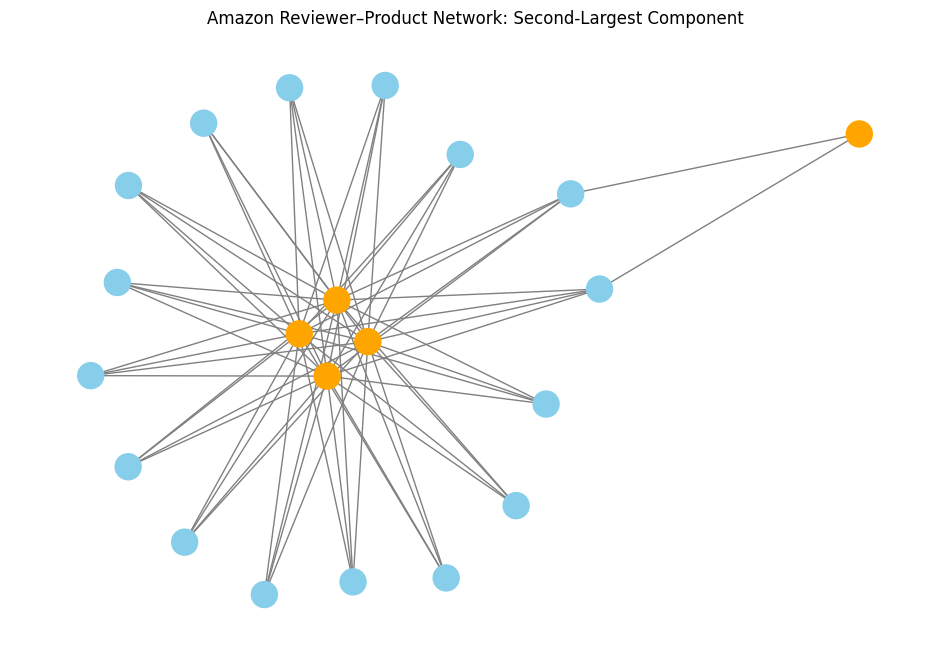

Nodes: 21
Edges: 66


In [77]:

# Step 24.7: Visualize the second-largest component

import networkx as nx
import matplotlib.pyplot as plt

# Extract the complete second-largest component
small_component = sub_B.subgraph(components[1]).copy()

# Color reviewers blue and products orange
node_colors = [
    "skyblue" if node.startswith("R_") else "orange"
    for node in small_component.nodes()
]

# Draw the network
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(small_component, seed=42)

nx.draw_networkx(
    small_component,
    pos,
    node_color=node_colors,
    node_size=350,
    edge_color="gray",
    with_labels=False
)

plt.title("Amazon Reviewer–Product Network: Second-Largest Component")
plt.axis("off")
plt.show()

print("Nodes:", small_component.number_of_nodes())
print("Edges:", small_component.number_of_edges())
